# Projct: Build a research Agent with Langraph, GPT-4o, Rang, Pinecode, Arxiv, and Google serpAPI


## Extrating Data from Arxiv into a Pandas Dataframe and Saving it as json

In [1]:
pip install -r requirements.txt -q 

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests
import pandas as pd
import json
import xml.etree.ElementTree as ET
import os

# Namespace for ArXiv's Atom-based XML format
ARXIV_NAMESPACE = "{http://www.w3.org/2005/Atom}"


def extract_from_arxiv(
    search_query="cat:cs.AI",
    max_results=100,
    json_file_path="files/arxiv_dataset.json"
):
    """
    Fetches papers from the ArXiv API based on a search query,
    saves them as JSON, and returns a pandas DataFrame.
    """

    # Construct the URL for the API request
    url = (
        f"http://export.arxiv.org/api/query?"
        f"search_query={search_query}"
        f"&max_results={max_results}"
    )

    # Send request to ArXiv
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    # Parse XML response
    root = ET.fromstring(response.content)

    # Store papers
    papers = []

    # Loop through each paper
    for entry in root.findall(f"{ARXIV_NAMESPACE}entry"):

        # -----------------------------
        # Title
        # -----------------------------
        title_element = entry.find(
            f"{ARXIV_NAMESPACE}title"
        )

        title = (
            title_element.text.strip()
            if title_element is not None
            else ""
        )

        # -----------------------------
        # Summary
        # -----------------------------
        summary_element = entry.find(
            f"{ARXIV_NAMESPACE}summary"
        )

        summary = (
            summary_element.text.strip()
            if summary_element is not None
            else ""
        )

        # -----------------------------
        # Authors
        # -----------------------------
        author_elements = entry.findall(
            f"{ARXIV_NAMESPACE}author"
        )

        authors = []

        for author in author_elements:

            name_element = author.find(
                f"{ARXIV_NAMESPACE}name"
            )

            if name_element is not None:
                authors.append(
                    name_element.text.strip()
                )

        # -----------------------------
        # ArXiv URL
        # -----------------------------
        id_element = entry.find(
            f"{ARXIV_NAMESPACE}id"
        )

        paper_url = (
            id_element.text.strip()
            if id_element is not None
            else ""
        )

        # -----------------------------
        # ArXiv ID
        # -----------------------------
        arxiv_id = paper_url.split("/")[-1]

        # -----------------------------
        # PDF LINK
        # -----------------------------
        pdf_link = f"https://arxiv.org/pdf/{arxiv_id}.pdf"

        # -----------------------------
        # Store paper
        # -----------------------------
        papers.append({
            "title": title,
            "summary": summary,
            "authors": authors,
            "arxiv_id": arxiv_id,
            "url": paper_url,
            "pdf_link": pdf_link
        })

    # Convert to DataFrame
    df = pd.DataFrame(papers)

    # Create directory
    directory = os.path.dirname(json_file_path)

    if directory:
        os.makedirs(
            directory,
            exist_ok=True
        )

    # Save JSON
    with open(
        json_file_path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            papers,
            f,
            indent=4,
            ensure_ascii=False
        )

    print(
        f"Successfully extracted {len(papers)} papers."
    )

    print(
        f"Data saved to: {json_file_path}"
    )

    return df


# ==========================================
# RUN
# ==========================================

df = extract_from_arxiv(
    search_query="cat:cs.AI",
    max_results=100,
    json_file_path="files/arxiv_dataset.json"
)

# Display title + PDF link
print(
    df[
        [
            "title",
            "arxiv_id",
            "pdf_link"
        ]
    ].head()
)

Successfully extracted 100 papers.
Data saved to: files/arxiv_dataset.json
                                               title      arxiv_id  \
0  A Deep Reinforcement Learning Approach for Ram...  2012.12104v1   
1  Rethink AI-based Power Grid Control: Diving In...  2012.13026v1   
2  Fuzzy Commitments Offer Insufficient Protectio...  2012.13293v1   
3  Generalization in portfolio-based algorithm se...  2012.13315v1   
4  I like fish, especially dolphins: Addressing C...  2012.13391v2   

                                 pdf_link  
0  https://arxiv.org/pdf/2012.12104v1.pdf  
1  https://arxiv.org/pdf/2012.13026v1.pdf  
2  https://arxiv.org/pdf/2012.13293v1.pdf  
3  https://arxiv.org/pdf/2012.13315v1.pdf  
4  https://arxiv.org/pdf/2012.13391v2.pdf  


In [3]:
import json

file_name = "files/arxiv_dataset.json"

with open(file_name, "r", encoding="utf-8") as file:
    data = json.load(file)

print(json.dumps(data[:2], indent=4, ensure_ascii=False))

[
    {
        "title": "A Deep Reinforcement Learning Approach for Ramp Metering Based on Traffic Video Data",
        "summary": "Ramp metering that uses traffic signals to regulate vehicle flows from the on-ramps has been widely implemented to improve vehicle mobility of the freeway. Previous studies generally update signal timings in real-time based on predefined traffic measures collected by point detectors, such as traffic volumes and occupancies. Comparing with point detectors, traffic cameras-which have been increasingly deployed on road networks-could cover larger areas and provide more detailed traffic information. In this work, we propose a deep reinforcement learning (DRL) method to explore the potential of traffic video data in improving the efficiency of ramp metering. The proposed method uses traffic video frames as inputs and learns the optimal control strategies directly from the high-dimensional visual inputs. A real-world case study demonstrates that, in comparison 

In [4]:
import pandas as pd
df=pd.DataFrame(data)
df.sample(5)

,title,summary,authors,arxiv_id,url,pdf_link
65,BHN: A Brain-like Heterogeneous Network,"The human brain works in an unsupervised way, ...",[Tao Liu],2005.12826v2,http://arxiv.org/abs/2005.12826v2,https://arxiv.org/pdf/2005.12826v2.pdf
24,ARCHANGEL: Tamper-proofing Video Archives usin...,We present ARCHANGEL; a novel distributed ledg...,"[Tu Bui, Daniel Cooper, John Collomosse, Mark ...",1904.12059v1,http://arxiv.org/abs/1904.12059v1,https://arxiv.org/pdf/1904.12059v1.pdf
94,Proof-Carrying Plans: a Resource Logic for AI ...,Recent trends in AI verification and Explainab...,"[Alasdair Hill, Ekaterina Komendantskaya, Rona...",2008.04165v2,http://arxiv.org/abs/2008.04165v2,https://arxiv.org/pdf/2008.04165v2.pdf
54,CAST: A Correlation-based Adaptive Spectral Cl...,We study the problem of applying spectral clus...,"[Xiang Li, Ben Kao, Caihua Shan, Dawei Yin, Ma...",2006.04435v1,http://arxiv.org/abs/2006.04435v1,https://arxiv.org/pdf/2006.04435v1.pdf
45,Options as responses: Grounding behavioural hi...,This paper investigates generalisation in mult...,"[Alexander Sasha Vezhnevets, Yuhuai Wu, Remi L...",1906.01470v3,http://arxiv.org/abs/1906.01470v3,https://arxiv.org/pdf/1906.01470v3.pdf


# Downloading the research papers(PDFs)

In [5]:
import os
import requests
import pandas as pd


def download_pdfs(df, download_folder="files"):
    """
    Downloads PDFs from URLs listed in the DataFrame and saves them
    to a specified folder.

    The file names are stored in a new column 'pdf_file_name'
    in the DataFrame.

    Args:
        df (pd.DataFrame): DataFrame containing a 'pdf_link' column
            with URLs to download.
        download_folder (str): Path to the folder where PDFs will
            be saved. Default is 'files'.

    Returns:
        pd.DataFrame: The original DataFrame with an additional
            'pdf_file_name' column containing the paths of the
            downloaded PDF files or None if the download failed.
    """

    # Create folder if it doesn't exist
    if not os.path.exists(download_folder):
        os.makedirs(download_folder)

    pdf_file_names = []

    # Loop through each row to download PDFs
    for index, row in df.iterrows():

        pdf_link = row["pdf_link"]

        try:
            # Send GET request to download PDF
            response = requests.get(pdf_link, timeout=30)

            # Raise an error if request was unsuccessful
            response.raise_for_status()

            # Create a PDF file name
            pdf_file_name = f"paper_{index}.pdf"

            # Full path for the PDF
            pdf_file_path = os.path.join(
                download_folder,
                pdf_file_name
            )

            # Save PDF to file
            with open(pdf_file_path, "wb") as pdf_file:
                pdf_file.write(response.content)

            pdf_file_names.append(pdf_file_path)

            print(f"Downloaded: {pdf_file_name}")

        except Exception as e:
            print(
                f"Failed to download PDF for row {index}: {e}"
            )

            pdf_file_names.append(None)

    # Add file names/paths to DataFrame
    df["pdf_file_name"] = pdf_file_names

    return df

In [6]:
df=download_pdfs(df)
df

Downloaded: paper_0.pdf
Downloaded: paper_1.pdf
Downloaded: paper_2.pdf
Downloaded: paper_3.pdf
Downloaded: paper_4.pdf
Downloaded: paper_5.pdf
Downloaded: paper_6.pdf
Downloaded: paper_7.pdf
Downloaded: paper_8.pdf
Downloaded: paper_9.pdf
Downloaded: paper_10.pdf
Downloaded: paper_11.pdf
Downloaded: paper_12.pdf
Downloaded: paper_13.pdf
Downloaded: paper_14.pdf
Downloaded: paper_15.pdf
Downloaded: paper_16.pdf
Downloaded: paper_17.pdf
Downloaded: paper_18.pdf
Downloaded: paper_19.pdf
Downloaded: paper_20.pdf
Downloaded: paper_21.pdf
Downloaded: paper_22.pdf
Downloaded: paper_23.pdf
Downloaded: paper_24.pdf
Downloaded: paper_25.pdf
Downloaded: paper_26.pdf
Downloaded: paper_27.pdf
Downloaded: paper_28.pdf
Downloaded: paper_29.pdf
Downloaded: paper_30.pdf
Downloaded: paper_31.pdf
Downloaded: paper_32.pdf
Downloaded: paper_33.pdf
Downloaded: paper_34.pdf
Downloaded: paper_35.pdf
Downloaded: paper_36.pdf
Downloaded: paper_37.pdf
Downloaded: paper_38.pdf
Downloaded: paper_39.pdf
Downloaded

,title,summary,authors,arxiv_id,url,pdf_link,pdf_file_name
0,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",2012.12104v1,http://arxiv.org/abs/2012.12104v1,https://arxiv.org/pdf/2012.12104v1.pdf,files\paper_0.pdf
1,Rethink AI-based Power Grid Control: Diving In...,"Recently, deep reinforcement learning (DRL)-ba...","[Xiren Zhou, Siqi Wang, Ruisheng Diao, Desong ...",2012.13026v1,http://arxiv.org/abs/2012.13026v1,https://arxiv.org/pdf/2012.13026v1.pdf,files\paper_1.pdf
2,Fuzzy Commitments Offer Insufficient Protectio...,"In this work, we study the protection that fuz...","[Danny Keller, Margarita Osadchy, Orr Dunkelman]",2012.13293v1,http://arxiv.org/abs/2012.13293v1,https://arxiv.org/pdf/2012.13293v1.pdf,files\paper_2.pdf
3,Generalization in portfolio-based algorithm se...,Portfolio-based algorithm selection has seen t...,"[Maria-Florina Balcan, Tuomas Sandholm, Ellen ...",2012.13315v1,http://arxiv.org/abs/2012.13315v1,https://arxiv.org/pdf/2012.13315v1.pdf,files\paper_3.pdf
4,"I like fish, especially dolphins: Addressing C...",To quantify how well natural language understa...,"[Yixin Nie, Mary Williamson, Mohit Bansal, Dou...",2012.13391v2,http://arxiv.org/abs/2012.13391v2,https://arxiv.org/pdf/2012.13391v2.pdf,files\paper_4.pdf
...,...,...,...,...,...,...,...
95,Risk-Sensitive Markov Decision Processes with ...,This paper investigates the optimization probl...,[Li Xia],2008.03707v1,http://arxiv.org/abs/2008.03707v1,https://arxiv.org/pdf/2008.03707v1.pdf,files\paper_95.pdf
96,Neural Manipulation Planning on Constraint Man...,The presence of task constraints imposes a sig...,"[Ahmed H. Qureshi, Jiangeng Dong, Austin Choe,...",2008.03787v1,http://arxiv.org/abs/2008.03787v1,https://arxiv.org/pdf/2008.03787v1.pdf,files\paper_96.pdf
97,Metaheuristics for the operating theater plann...,There are found a vast number of papers studyi...,"[Amirhossein Moosavi, Onur Ozturk]",2008.04970v1,http://arxiv.org/abs/2008.04970v1,https://arxiv.org/pdf/2008.04970v1.pdf,files\paper_97.pdf
98,Sistema experto para el diagnóstico de enferme...,Agricultural production has become a complex b...,"[Ing. Yosvany Medina Carbó, MSc. Iracely Milag...",2007.11038v1,http://arxiv.org/abs/2007.11038v1,https://arxiv.org/pdf/2007.11038v1.pdf,files\paper_98.pdf


# Loading and splitting PDF files into chucks, Expanding the dataFrame

In [7]:
pip install -U langchain-community langchain-text-splitters pypdf

Note: you may need to restart the kernel to use updated packages.


In [8]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter


def load_and_chunk_pdf(pdf_file_name, chunk_size=512):
    """
    Loads a PDF file and splits its content into chunks.
    """

    print(f"Loading and splitting into chunks: {pdf_file_name}")

    # Load PDF
    loader = PyPDFLoader(pdf_file_name)
    documents = loader.load()

    print(f"Loaded {len(documents)} pages.")

    # Create text splitter
    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=50
    )

    # Split documents into chunks
    chunks = text_splitter.split_documents(documents)

    print(f"Created {len(chunks)} chunks.")

    return chunks

C:\Users\Rinku\AppData\Local\Temp\ipykernel_1356\1869955217.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [9]:
def expand_df(df):
    """
    Expands each row in the DataFrame by splitting PDF documents
    into chunks.

    Args:
        df (pd.DataFrame): DataFrame containing:
            'pdf_file_name', 'arxiv_id', 'title', 'summary',
            'authors', and 'url' columns.

    Returns:
        pd.DataFrame: A new DataFrame where each row represents
        a chunk of the original document, with metadata.
    """

    expanded_rows = []  # List to store expanded rows

    # Loop through each row in the DataFrame
    for index, row in df.iterrows():

        print(
            f"Processing PDF {index + 1}/{len(df)}: "
            f"{row['pdf_file_name']}"
        )

        # Load and split PDF into chunks
        chunks = load_and_chunk_pdf(
            row["pdf_file_name"],
            chunk_size=512
        )

        # Loop through each chunk
        for chunk_index, chunk in enumerate(chunks):

            # Create a new row for each chunk
            expanded_rows.append({
                "arxiv_id": row["arxiv_id"],
                "title": row["title"],
                "summary": row["summary"],
                "authors": row["authors"],
                "url": row["url"],
                "pdf_file_name": row["pdf_file_name"],

                # Chunk information
                "chunk_id": chunk_index,
                "chunk_text": chunk.page_content,

                # Page number from PDF metadata
                "page": chunk.metadata.get("page"),

                # Total number of chunks
                "total_chunks": len(chunks)
            })

    # Convert expanded rows to DataFrame
    expanded_df = pd.DataFrame(expanded_rows)

    return expanded_df

In [10]:
expanded_df = expand_df(df)

Processing PDF 1/100: files\paper_0.pdf
Loading and splitting into chunks: files\paper_0.pdf
Loaded 15 pages.
Created 76 chunks.
Processing PDF 2/100: files\paper_1.pdf
Loading and splitting into chunks: files\paper_1.pdf
Loaded 8 pages.
Created 56 chunks.
Processing PDF 3/100: files\paper_2.pdf
Loading and splitting into chunks: files\paper_2.pdf
Loaded 13 pages.
Created 154 chunks.
Processing PDF 4/100: files\paper_3.pdf
Loading and splitting into chunks: files\paper_3.pdf
Loaded 23 pages.
Created 146 chunks.
Processing PDF 5/100: files\paper_4.pdf
Loading and splitting into chunks: files\paper_4.pdf
Loaded 15 pages.
Created 135 chunks.
Processing PDF 6/100: files\paper_5.pdf
Loading and splitting into chunks: files\paper_5.pdf
Loaded 10 pages.
Created 155 chunks.
Processing PDF 7/100: files\paper_6.pdf
Loading and splitting into chunks: files\paper_6.pdf
Loaded 5 pages.
Created 46 chunks.
Processing PDF 8/100: files\paper_7.pdf
Loading and splitting into chunks: files\paper_7.pdf
Lo

fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/OROFQM+SFRM0900', '/FontDescriptor': IndirectObject(32, 0, 3090799642704), '/Type': '/Font', '/FirstChar': 183, '/LastChar': 183, '/Widths': [285], '/Encoding': '/WinAnsiEncoding', '/Subtype': '/Type1'}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/CFCOJD+CMBX9', '/FontDescriptor': IndirectObject(30, 0, 3090799642704), '/Type': '/Font', '/FirstChar': 46, '/LastChar': 121, '/Widths': [328, 0, 591, 591, 591, 591, 591, 591, 0, 0, 591, 591, 328, 0, 0, 0, 0, 0, 0, 892, 0, 0, 0, 0, 0, 0, 0, 0, 0, 925, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 575, 657, 525, 657, 542, 0, 0, 0, 0, 0, 0, 0, 0, 0, 591, 0, 0, 488, 466, 460, 0, 0, 854, 0, 624], '/Encoding': '/WinAnsiEncoding', '/Subtype': '/Type1'}, but is not installed. Conside

Loaded 12 pages.
Created 70 chunks.
Processing PDF 10/100: files\paper_9.pdf
Loading and splitting into chunks: files\paper_9.pdf


fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/GJDTSN+CMR6', '/FontDescriptor': IndirectObject(26, 0, 3090799642704), '/Type': '/Font', '/FirstChar': 49, '/LastChar': 52, '/Widths': [611, 611, 611, 611], '/Encoding': '/WinAnsiEncoding', '/Subtype': '/Type1'}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/WYSWPH+CMR7', '/FontDescriptor': IndirectObject(24, 0, 3090799642704), '/Type': '/Font', '/FirstChar': 49, '/LastChar': 52, '/Widths': [569, 569, 569, 569], '/Encoding': '/WinAnsiEncoding', '/Subtype': '/Type1'}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/XRYUAM+CMR10', '/FontDescriptor': IndirectObject(22, 0, 3090799642704), '/Type': '/

Loaded 14 pages.
Created 86 chunks.
Processing PDF 11/100: files\paper_10.pdf
Loading and splitting into chunks: files\paper_10.pdf
Loaded 14 pages.
Created 127 chunks.
Processing PDF 12/100: files\paper_11.pdf
Loading and splitting into chunks: files\paper_11.pdf
Loaded 7 pages.
Created 51 chunks.
Processing PDF 13/100: files\paper_12.pdf
Loading and splitting into chunks: files\paper_12.pdf
Loaded 8 pages.
Created 44 chunks.
Processing PDF 14/100: files\paper_13.pdf
Loading and splitting into chunks: files\paper_13.pdf
Loaded 9 pages.
Created 46 chunks.
Processing PDF 15/100: files\paper_14.pdf
Loading and splitting into chunks: files\paper_14.pdf


...

Loaded 15 pages.
Created 155 chunks.
Processing PDF 95/100: files\paper_94.pdf
Loading and splitting into chunks: files\paper_94.pdf


fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/UQMDRJ+txsyc', '/FontDescriptor': IndirectObject(113, 0, 3090789900576), '/Type': '/Font', '/FirstChar': 123, '/LastChar': 123, '/Widths': [1009], '/Encoding': IndirectObject(489, 0, 3090789900576), '/Subtype': '/Type1'}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/YTTHNZ+LibertineMathBMI', '/FontDescriptor': IndirectObject(176, 0, 3090789900576), '/Type': '/Font', '/FirstChar': 101, '/LastChar': 116, '/Widths': [415, 483, 0, 551, 236, 0, 0, 251, 0, 551, 0, 0, 0, 0, 373, 285], '/Encoding': IndirectObject(473, 0, 3090789900576), '/Subtype': '/Type1'}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont'

Loaded 13 pages.
Created 189 chunks.
Processing PDF 96/100: files\paper_95.pdf
Loading and splitting into chunks: files\paper_95.pdf


fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/UFLPVQ+CMMI6', '/FontDescriptor': IndirectObject(131, 0, 3090789906576), '/Type': '/Font', '/FirstChar': 14, '/LastChar': 109, '/Widths': [566, 0, 0, 0, 0, 0, 0, 0, 750, 0, 0, 0, 0, 716, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 379, 0, 0, 0, 0, 0, 924, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 731, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 674, 0, 0, 642, 0, 0, 0, 0, 445, 0, 0, 401, 1093], '/Encoding': IndirectObject(943, 0, 3090789906576), '/Subtype': '/Type1'}, but is not installed. Consider installing fontTools if you encounter encoding problems.
fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/YGZADT+CMR12', '/FontDescriptor': IndirectObject(29, 0, 3090789906576), '/Type': '/Font', '/FirstChar': 1, '/LastChar': 127, '/Widths': [815, 0, 0, 0, 0, 0, 0, 0, 761, 0, 571, 

Loaded 43 pages.
Created 197 chunks.
Processing PDF 97/100: files\paper_96.pdf
Loading and splitting into chunks: files\paper_96.pdf
Loaded 8 pages.
Created 87 chunks.
Processing PDF 98/100: files\paper_97.pdf
Loading and splitting into chunks: files\paper_97.pdf
Loaded 31 pages.
Created 143 chunks.
Processing PDF 99/100: files\paper_98.pdf
Loading and splitting into chunks: files\paper_98.pdf
Loaded 19 pages.
Created 84 chunks.
Processing PDF 100/100: files\paper_99.pdf
Loading and splitting into chunks: files\paper_99.pdf
Loaded 11 pages.
Created 91 chunks.


## Building a Knowledge Base for the RAG System using Embedding

In [11]:
import os
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv(), override=True)

True

In [12]:
import os
from getpass import getpass

from semantic_router.encoders import OpenAIEncoder

os.environ['OPENAPI_API_KEY']= os.getenv('OPENAPI_API_KEY') or getpass('OpenApi API Key: ')

encoder=OpenAIEncoder(name='text-embedding-3-small')

OpenApi API Key:  ········


In [13]:
encoder('hello sankirna')

[[0.0136871337890625,
  0.00644683837890625,
  0.01934814453125,
  0.0301666259765625,
  0.0152130126953125,
  0.002063751220703125,
  -0.0031528472900390625,
  0.050933837890625,
  -0.01546478271484375,
  -0.050018310546875,
  0.01287841796875,
  -0.0015058517456054688,
  -0.07098388671875,
  -0.00457000732421875,
  0.0245208740234375,
  0.01287078857421875,
  -0.024017333984375,
  -0.0032444000244140625,
  0.014251708984375,
  0.041534423828125,
  -0.0208892822265625,
  0.033721923828125,
  0.041168212890625,
  0.039276123046875,
  0.0074005126953125,
  -0.0093841552734375,
  -0.0105133056640625,
  -0.01393890380859375,
  0.0289459228515625,
  -0.01556396484375,
  0.034759521484375,
  -0.03277587890625,
  0.02716064453125,
  -0.02923583984375,
  -0.007694244384765625,
  0.04412841796875,
  -0.049346923828125,
  0.04315185546875,
  -0.0268402099609375,
  0.0228271484375,
  -0.0103302001953125,
  0.00020372867584228516,
  -0.001781463623046875,
  -0.0211181640625,
  0.0316162109375,
  

encoder('hello sankirna')[0]

# creating a Pintcone Index

In [14]:
from pinecone import Pinecone, ServerlessSpec

api_key= os.getenv('PINECONE_API_KEY') or getpass('PINECONE_API_KEY API Key: ')

pc = Pinecone(api_key=api_key)

spec=ServerlessSpec(
    cloud='aws',
    region='us-east-1'
)

In [15]:
import time

index_name='langgraph-search-agent'

if index_name not in pc.list_indexes().names():
    pc.create_index(
        index_name,
        dimension=1536,
        metric='cosine',
        spec=spec
    )

    while not pc.describe_index(index_name).status['ready']:
        time.sleep(1)

index= pc.Index(index_name)

time.sleep(1)

index.describe_index_stats()

{'dimension': 1536,
 'index_fullness': 0.0,
 'metric': 'cosine',
 'namespaces': {},
 'total_vector_count': 0,
 'vector_type': 'dense'}

In [17]:
expanded_df.iloc[:5]

,arxiv_id,title,summary,authors,url,pdf_file_name,chunk_id,chunk_text,page,total_chunks
0,2012.12104v1,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",http://arxiv.org/abs/2012.12104v1,files\paper_0.pdf,0,1 \nA Deep Reinforcement Learning Approach for...,0,76
1,2012.12104v1,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",http://arxiv.org/abs/2012.12104v1,files\paper_0.pdf,1,Abstract \nRamp metering that uses traffic sig...,0,76
2,2012.12104v1,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",http://arxiv.org/abs/2012.12104v1,files\paper_0.pdf,2,and provide more detailed traffic information....,0,76
3,2012.12104v1,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",http://arxiv.org/abs/2012.12104v1,files\paper_0.pdf,3,method results in 1) lower travel times in the...,0,76
4,2012.12104v1,A Deep Reinforcement Learning Approach for Ram...,Ramp metering that uses traffic signals to reg...,"[Bing Liu, Yu Tang, Yuxiong Ji, Yu Shen, Yuchu...",http://arxiv.org/abs/2012.12104v1,files\paper_0.pdf,4,2 \nIntroduction \nRamp metering uses traffic ...,1,76


In [19]:
from tqdm.auto import tqdm

data = expanded_df
batch_size = 64

for i in tqdm(range(0, len(data), batch_size)):

    i_end = min(len(data), i + batch_size)

    batch = data.iloc[i:i_end].to_dict(orient="records")

    # Extract metadata
    metadata = [
        {
            "arxiv_id": r["arxiv_id"],
            "title": r["title"],
            "chunk": r["chunk_text"]
        }
        for r in batch
    ]

    # Generate unique IDs
    ids = [
        f"{r['arxiv_id']}_{r['chunk_id']}"
        for r in batch
    ]

    # Extract chunk content
    chunks = [
        r["chunk_text"]
        for r in batch
    ]

    # Convert chunks into embeddings
    embeds = encoder(chunks)

    # Upload embeddings, IDs and metadata to Pinecone
    index.upsert(
        vectors=zip(ids, embeds, metadata)
    )

print("All embeddings uploaded successfully!")

  0%|          | 0/181 [00:00<?, ?it/s]

All embeddings uploaded successfully!


## implemntion the ArXiv Fetch tool

In [21]:
import requests

arxiv_id='1706.03762'

 # Construct the URL for the API request
url = f"https://arxiv.org/abs/{arxiv_id}"


# Send request to ArXiv
res = requests.get(url)

res.text

'<!DOCTYPE html>\n<html lang="en">\n\n<head><script>document.documentElement.classList.add(\'js\');</script>  <title>[1706.03762] Attention Is All You Need</title>\n  <meta name="viewport" content="width=device-width, initial-scale=1">\n  <link rel="apple-touch-icon" sizes="180x180" href="/static/browse/0.3.4/images/icons/apple-touch-icon.png">\n  <link rel="icon" type="image/png" sizes="32x32" href="/static/browse/0.3.4/images/icons/favicon-32x32.png">\n  <link rel="icon" type="image/png" sizes="16x16" href="/static/browse/0.3.4/images/icons/favicon-16x16.png">\n  <link rel="manifest" href="/static/browse/0.3.4/images/icons/site.webmanifest">\n  <link rel="mask-icon" href="/static/browse/0.3.4/images/icons/safari-pinned-tab.svg" color="#5bbad5">\n  <meta name="msapplication-TileColor" content="#da532c">\n  <meta name="theme-color" content="#ffffff">\n  <link rel="stylesheet" type="text/css" media="screen" href="/static/browse/0.3.4/css/arXiv.css?v=20260318" />\n  <link rel="stylesheet

In [23]:
import re

# Compile a regular expression pattern to find the abstract in the HTML response
abstract_pattern = re.compile(
    r'<blockquote class="abstract mathjax">\s*<span class="descriptor">Abstract:</span>\s*(.*?)\s*</blockquote>',
    re.DOTALL
)

re_match=abstract_pattern.search(res.text)

if re_match:
    print(re_match.group(1))
else:
    print('not found')
    

The dominant sequence transduction models are based on complex recurrent or convolutional neural networks in an encoder-decoder configuration. The best performing models also connect the encoder and decoder through an attention mechanism. We propose a new simple network architecture, the Transformer, based solely on attention mechanisms, dispensing with recurrence and convolutions entirely. Experiments on two machine translation tasks show these models to be superior in quality while being more parallelizable and requiring significantly less time to train. Our model achieves 28.4 BLEU on the WMT 2014 English-to-German translation task, improving over the existing best results, including ensembles by over 2 BLEU. On the WMT 2014 English-to-French translation task, our model establishes a new single-model state-of-the-art BLEU score of 41.8 after training for 3.5 days on eight GPUs, a small fraction of the training costs of the best models from the literature. We show that the Transforme

In [25]:
import requests
from langchain_core.tools import tool
import re

# Compile a regular expression pattern to find the abstract in the HTML response
abstract_pattern = re.compile(
    r'<blockquote class="abstract mathjax">\s*<span class="descriptor">Abstract:</span>\s*(.*?)\s*</blockquote>',
    re.DOTALL
)

@tool('fetch_arxiv')
def fetch_arxiv(arxiv_id: str) -> str:
    """
    Fetches the abstract from an ArXiv paper given its ArXiv ID.

    Args:
        arxiv_id (str): The ArXiv paper ID.

    Returns:
        str: The extracted abstract text from the ArXiv paper.
    """

    res = requests.get(
        f"https://arxiv.org/abs/{arxiv_id}"
    )

    re_match = abstract_pattern.search(res.text)

    return (
        re_match.group(1)
        if re_match
        else "Abstract not found."
    )

In [26]:

arxiv_id='1706.03762'
output= fetch_arxiv.invoke(input={'arxiv_id':arxiv_id})
output

'The dominant sequence transduction models are based on complex recurrent or convolutional neural networks in an encoder-decoder configuration. The best performing models also connect the encoder and decoder through an attention mechanism. We propose a new simple network architecture, the Transformer, based solely on attention mechanisms, dispensing with recurrence and convolutions entirely. Experiments on two machine translation tasks show these models to be superior in quality while being more parallelizable and requiring significantly less time to train. Our model achieves 28.4 BLEU on the WMT 2014 English-to-German translation task, improving over the existing best results, including ensembles by over 2 BLEU. On the WMT 2014 English-to-French translation task, our model establishes a new single-model state-of-the-art BLEU score of 41.8 after training for 3.5 days on eight GPUs, a small fraction of the training costs of the best models from the literature. We show that the Transform

## Integrating Google SerpAPi Tool with Google serpAPI

In [27]:

from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv(), override=True)

True

In [31]:
from serpapi import GoogleSearch
import os
from getpass import getpass

serpapi_params = {
    "engine": "google",
    "api_key": os.getenv("SERPAPI_KEY") or getpass("SerpAPI key: "),
}

# Perform a Google search for the keyword "water" and limit the results to 5.
search = GoogleSearch({
    **serpapi_params,
    "q": "water",
    "num": 5
})

# Extract the main search results from the API response.
results = search.get_dict().get("organic_results", [])

# Format the search results for readability.
formatted_results = "\n....\n".join(
    [
        "\n".join([
            x["title"],
            x["snippet"],
            x["link"]
        ])
        for x in results
    ]
)

In [33]:
print(formatted_results)

Tag: Alkaline water
THE BENEFITS OF ALKALINE WATER. Nicolet alkaline water has a higher pH level than drinking water and contains electrolytes for a great-tasting hydration ...
https://premiumwaters.com/blog/tag/alkaline-water/
....
Constantly sipping water is BAD FOR TEETH!
Why Sipping Water Can Harm Your Teeth (How To Fix It) gums, pockets, and cavities getting worse? Your mouth can heal, small mistakes can stall ...
https://www.youtube.com/shorts/Q2pQ1_IFZbs
....
AI's water problems run deep
The water footprint everyone's tracking may only be a fraction of what AI's growth actually costs communities and infrastructure.
https://www.fastcompany.com/91591272/ais-water-problems-run-deep
....
Water Retention as a Measurable Goal of Water Governance
For much of the twentieth century, water policy in many countries was shaped by efforts to augment supply. Dams, canals, reservoirs, and ...
https://www.orfonline.org/expert-speak/water-retention-as-a-measurable-goal-of-water-governance
....
N

In [35]:
import os
from getpass import getpass
from serpapi import GoogleSearch
from langchain_core.tools import tool


# SerpAPI configuration
serpapi_params = {
    "engine": "google",
    "api_key": os.getenv("SERPAPI_KEY") or getpass("SerpAPI key: ")
}


@tool("web_search")
def web_search(query: str) -> str:
    """
    Performs a Google search using SerpAPI.

    Args:
        query: Search query.

    Returns:
        Formatted search results.
    """

    # Perform Google search
    search = GoogleSearch({
        **serpapi_params,
        "q": query,
        "num": 5
    })

    # Get search results
    results = search.get_dict().get(
        "organic_results",
        []
    )

    # Format results
    formatted_results = "\n....\n".join(
        [
            "\n".join([
                x.get("title", ""),
                x.get("snippet", ""),
                x.get("link", "")
            ])
            for x in results
        ]
    )

    return (
        formatted_results
        if results
        else "Search not found."
    )

In [36]:
query='who is google'
output= web_search.invoke(input={'query':query})
print(output)

Who Am I Academy
„Who Am I Academy“ yra internetinė platforma, skirta tiesioginiams užsiėmimams, internetiniams testams vesti. Tai viena platforma, kurioje mokytojai, ...
https://play.google.com/store/apps/details?id=com.ingenium.tca1492&hl=lt
....
Who is who in Lithuania
Bibliographic information ; Title, Who is who in Lithuania ; Publisher, Kas yra kas Lietuvoje, UAB Neolitas, 2004 ; ISBN, 9986709490, 9789986709497 ; Export ...
https://books.google.com/books/about/Who_is_who_in_Lithuania.html?id=ccIiAQAAIAAJ
....
Google gives wrong answer I asked Google assistant who ...
That IS the correct answer. Biden won't actually be President until he is sworn in on January 20, 2021. Right now his correct title is President ...
https://support.google.com/mail/thread/82187376/google-gives-wrong-answer-i-asked-google-assistant-who-is-present-president-of-usa?hl=en
....
Is Google not working on WiFi and 4G for others?
Looks to be an issue with JT access to Google and related services. Google searc

## Creating RAG Tool for Retrieval-Augmented Generation(RAG)

In [37]:
def format_rag_contexts(matches: list) -> str:
    """
    Formats the retrieved context matches into a readable string format.

    Args:
        matches (list): A list of matched documents with metadata.

    Returns:
        str: A formatted string of document titles, chunks, and ArXiv IDs.
    """

    formatted_results = []

    # Loop through each match and extract its metadata
    for x in matches:
        text = (
            f"Title: {x['metadata']['title']}\n"
            f"Chunk: {x['metadata']['chunk']}\n"
            f"ArXiv ID: {x['metadata']['arxiv_id']}\n"
        )

        # Append each formatted string to the results list
        formatted_results.append(text)

    # Join all individual formatted strings into one large string
    return "\n---\n".join(formatted_results)

In [38]:
from langchain_core.tools import tool


@tool
def rag_search_filter(query: str, arxiv_id: str) -> str:
    """
    Finds information from the ArXiv database using a natural language
    query and a specific ArXiv ID.

    Args:
        query (str): The search query in natural language.
        arxiv_id (str): The ArXiv ID of the specific paper to filter by.

    Returns:
        str: A formatted string of relevant document contexts.
    """

    # Encode the query into a vector representation
    xq = encoder([query])

    # Perform a search on the Pinecone index, filtering by ArXiv ID
    xc = index.query(
        vector=xq,
        top_k=6,
        include_metadata=True,
        filter={"arxiv_id": arxiv_id}
    )

    # Format and return the search results
    return format_rag_contexts(xc["matches"])

In [39]:
from langchain_core.tools import tool


@tool("rag_search")
def rag_search(query: str) -> str:
    """
    Finds specialist information on AI using a natural language query.

    Args:
        query (str): The search query in natural language.

    Returns:
        str: A formatted string of relevant document contexts.
    """

    # Encode the query into a vector representation
    xq = encoder([query])

    # Perform a broader search without filtering by ArXiv ID
    xc = index.query(
        vector=xq,
        top_k=5,
        include_metadata=True
    )

    # Format and return the search results
    return format_rag_contexts(xc["matches"])

## Final asnwer tool

In [40]:
from langchain_core.tools import tool


# Define the 'final_answer' tool to compile the research report.
@tool
def final_answer(
    introduction: str,
    research_steps: str | list,
    main_body: str,
    conclusion: str,
    sources: str | list
) -> str:
    """
    Returns a natural language response in the form of a research report.

    Args:
        introduction (str): A short paragraph introducing the user's question
            and the topic.
        research_steps (str or list): Bullet points or text explaining the
            steps taken for research.
        main_body (str): The bulk of the answer, 3-4 paragraphs long,
            providing high-quality information.
        conclusion (str): A short paragraph summarizing the findings.
        sources (str or list): A list or text providing the sources referenced
            during the research.

    Returns:
        str: A formatted research report string.
    """

    # Format research steps if given as a list.
    if isinstance(research_steps, list):
        research_steps = "\n".join(
            f"- {r}" for r in research_steps
        )

    # Format sources if given as a list.
    if isinstance(sources, list):
        sources = "\n".join(
            f"- {s}" for s in sources
        )

    # Construct and return the final research report.
    return (
        f"{introduction}\n\n"
        f"Research Steps:\n{research_steps}\n\n"
        f"Main Body:\n{main_body}\n\n"
        f"Conclusion:\n{conclusion}\n\n"
        f"Sources:\n{sources}"
    )

## Initailizing the Oracle LLM

In [42]:
from langchain_core.prompts import (
    ChatPromptTemplate,
    MessagesPlaceholder
)

# Define the system prompt guiding the AI's decision-making process
system_prompt = """
You are the oracle, the great AI decision-maker.

Given the user's query, you must decide what to do with it based on the
list of tools provided to you.

If you see that a tool has been used (in the scratchpad) with a particular
query, do NOT use that same tool with the same query again. Also, do NOT use
any tool more than twice (i.e., if the tool appears in the scratchpad twice,
do not use it again).

You should aim to collect information from a diverse range of sources before
providing the answer to the user.

Once you have collected plenty of information to answer the user's question
(stored in the scratchpad), use the final_answer tool.
"""

# Create a prompt template for the conversation flow
prompt = ChatPromptTemplate.from_messages([
    # Define the AI's role and rules
    ("system", system_prompt),

    # Insert past chat messages to maintain context
    MessagesPlaceholder(variable_name="chat_history"),

    # Insert user's input dynamically
    ("user", "{input}"),

    # Include the assistant's scratchpad to track tool usage
    # and intermediate steps
    ("assistant", "scratchpad: {scratchpad}"),
])

In [43]:
from langchain_core.messages import ToolCall, ToolMessage
from langchain_openai import ChatOpenAI
import os


# Initialize the OpenAI language model with specific settings
llm = ChatOpenAI(
    model="gpt-4o",
    openai_api_key=os.environ["OPENAI_API_KEY"],
    temperature=0
)


# Define the list of tools available to the oracle
tools = [
    rag_search_filter,
    rag_search,
    fetch_arxiv,
    web_search,
    final_answer
]




In [45]:
# Function to create the scratchpad from the intermediate tool calls
def create_scratchpad(intermediate_steps: list[ToolCall]) -> str:
    research_steps = []

    # Loop over each step and process tool calls with actual outputs
    for i, action in enumerate(intermediate_steps):
        if action.log != "TBD":
            research_steps.append(
                f"Tool: {action.tool}, input: {action.tool_input}\n"
                f"Output: {action.log}"
            )

    # Join the research steps into a readable log
    return "\n---\n".join(research_steps)

In [46]:
# Define the oracle's decision-making pipeline.
oracle = (
    {
        "input": lambda x: x["input"],
        "chat_history": lambda x: x["chat_history"],
        "scratchpad": lambda x: create_scratchpad(
            intermediate_steps=x["intermediate_steps"]
        ),
    }
    | prompt
    | llm.bind_tools(tools, tool_choice="any")
)

### Testing the Oracle and the tools

In [51]:
input = "Tell me something interesting about arxiv"

# Create the inputs dictionary, containing the user's query,
# initial empty chat history, and intermediate steps.
inputs = {
    "input": input,
    "chat_history": [],
    "intermediate_steps": [],
}

# Invoke the oracle with the inputs.
out = oracle.invoke(inputs)

# Display the oracle's response.
print(out)

content='' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 19, 'prompt_tokens': 579, 'total_tokens': 598, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_f1fdc30c4a', 'id': 'chatcmpl-EToHMNlhVlsAZ1zVB0dXX6auNCi8i', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None} id='lc_run--01a0f26a-f85c-7af3-9aeb-fcef945ea948-0' tool_calls=[{'name': 'web_search', 'args': {'query': 'interesting facts about arXiv'}, 'id': 'call_VKNZeX0yOGcYYhRGx2R6hdOS', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 579, 'output_tokens': 19, 'total_tokens': 598, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0

In [53]:
out.tool_calls[0]['name']
out.tool_calls[0]['args']

{'query': 'interesting facts about arXiv'}

### Building a Decision-making pipeline

In [65]:
# The run_tool() function executes the appropriate tool based on the current state.
def run_tool(state: dict) -> dict:
    '''Executes the appropriate tool based on the current state.

    Args:
        state (dict): The current state containing the 'intermediate_steps'.

    Returns:
        dict: A new state with updated 'intermediate_steps' including the tool's result.
    '''

    tool_name = state['intermediate_steps'][-1].tool
    tool_args = state['intermediate_steps'][-1].tool_input

    print(f'{tool_name}.invoke(input={tool_args})')

    tool_str_to_func = {
    'rag_search_filter': rag_search_filter,
    'rag_search': rag_search,
    'fetch_arxiv': fetch_arxiv,
    'web_search': web_search,
    'final_answer': final_answer,
}

    out = tool_str_to_func[tool_name].invoke(input=tool_args)

    action_out = AgentAction(
        tool=tool_name,
        tool_input=tool_args,
        log=str(out)
    )

    return {
        'intermediate_steps': [action_out]
    }

In [58]:
def run_oracle(state: dict) -> dict:
    """
    Runs the oracle and processes the output to extract tool information.

    Args:
        state (dict): The current state containing the 'intermediate_steps'.

    Returns:
        dict: A new state with updated 'intermediate_steps'
              including the tool action.
    """

    print("run_oracle")
    print(f"intermediate_steps: {state['intermediate_steps']}")

    out = oracle.invoke(state)

    # Extract the tool call from the oracle's response
    if hasattr(out, "tool_calls") and out.tool_calls:
        tool_call = out.tool_calls[0]

        tool_name = tool_call["name"]
        tool_args = tool_call["args"]

        action_out = AgentAction(
            tool=tool_name,
            tool_input=tool_args,
            log=str(out)
        )

        return {
            "intermediate_steps": [action_out]
        }

    # No tool call was generated
    return {
        "intermediate_steps": []
    }

In [55]:
# The router() function determines the next tool to use based on the current state.
def router(state: dict) -> str:
    """Determines the next tool to use based on the current state.

    Args:
        state (dict): The current state containing 'intermediate_steps'.

    Returns:
        str: The name of the tool to use next.
    """

    if isinstance(state['intermediate_steps'], list):
        return state['intermediate_steps'][-1].tool
    else:
        print('Router invalid format')
        return 'final_answer'

### Define the Agent State

In [57]:
from typing import TypedDict, Annotated, List
from langchain_core.agents import AgentAction
from langchain_core.messages import BaseMessage
import operator


class AgentState(TypedDict):
    """Represents the state of an agent."""

    input: str
    chat_history: List[BaseMessage]
    intermediate_steps: Annotated[
        List[tuple[AgentAction, str]],
        operator.add
    ]

### Define the graph for decision making

In [66]:
from langgraph.graph import StateGraph, END

# Initialize the state graph with AgentState to manage the workflow.
graph = StateGraph(AgentState)

graph.add_node('oracle', run_oracle)
graph.add_node('rag_search_filter', run_tool)
graph.add_node('rag_search', run_tool)
graph.add_node('fetch_arxiv', run_tool)
graph.add_node('web_search', run_tool)
graph.add_node('final_answer', run_tool)

# Set the entry point to 'oracle'.
graph.set_entry_point('oracle')
# Add conditional edges to determine the next step using the router function.
graph.add_conditional_edges(source='oracle', path=router)

# Add edges from each tool back to 'oracle', except 'final_answer',
# which leads to 'END'.
for tool_obj in tools:
    if tool_obj.name != 'final_answer':
        graph.add_edge(tool_obj.name, 'oracle')

graph.add_edge('final_answer', END)

# Compile the graph to make it executable.
runnable = graph.compile()
                      

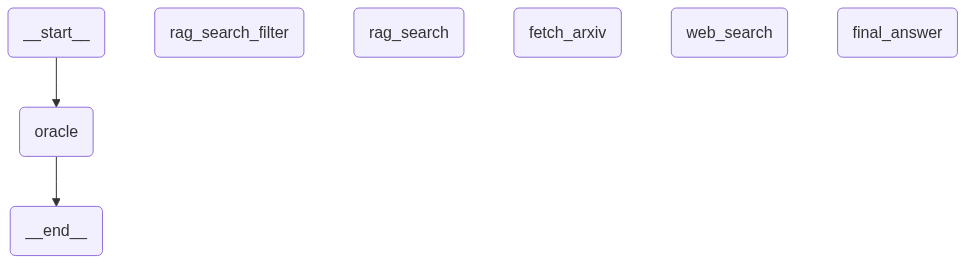

In [67]:
from IPython.display import Image, display

# Display the graph as a PNG using Mermaid rendering.
display(Image(runnable.get_graph().draw_mermaid_png()))

In [ ]:
# Run the graph with input.
output = runnable.invoke({
    'input': 'Tell me something interesting about Dynamic Backtracking AI and LLMs',
    'chat_history': [],
})

### Generate Reports

In [69]:
output['intermediate_steps'][-1]

AgentAction(tool='final_answer', tool_input={'introduction': 'Dynamic Backtracking AI and Large Language Models (LLMs) are two fascinating areas in the field of artificial intelligence, each with unique applications and methodologies. Dynamic Backtracking AI focuses on problem-solving techniques, while LLMs are designed to understand and generate human-like text.', 'research_steps': ["Conducted a RAG search for 'Dynamic Backtracking AI' to gather information on its applications and methodologies.", 'Performed a web search to find additional insights and examples of Dynamic Backtracking AI in practice.', "Conducted a RAG search for 'LLMs (Large Language Models)' to understand their structure and applications.", 'Performed a web search to gather more comprehensive information on LLMs and their impact on AI.'], 'main_body': "Dynamic Backtracking AI is a problem-solving technique that involves exploring possible solutions incrementally and backtracking when a deadlock or failure occurs. Th

In [76]:
def build_report(output: dict) -> str:
    """Builds a formatted report based on the oracle's output.

    Args:
        output (dict): A dictionary containing the various sections of the report (graph's output).

    Returns:
        str: A formatted string containing the full research report.
    """

    research_steps = output['research_steps']
    if isinstance(research_steps, list):
        research_steps = '\n'.join([f'- {r}' for r in research_steps])

    sources = output['sources']
    if isinstance(sources, list):
        sources = '\n'.join([f'- {s}' for s in sources])

    return f"""
            INTRODUCTION
            ------------
            {output['introduction']}
            
            RESEARCH STEPS
            --------------
            {research_steps}
            """

In [73]:
# Run the graph with input.
output = runnable.invoke({
    'input': 'Tell me something interesting about Dynamic Backtracking AI and LLMs',
    'chat_history': [],
})

run_oracle
intermediate_steps: []
rag_search.invoke(input={'query': 'Dynamic Backtracking AI'})
run_oracle
intermediate_steps: [AgentAction(tool='rag_search', tool_input={'query': 'Dynamic Backtracking AI'}, log="content='' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 55, 'prompt_tokens': 585, 'total_tokens': 640, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_f1fdc30c4a', 'id': 'chatcmpl-ETpArMujtaIsTPdTXNdAvdoGiiabv', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None} id='lc_run--01a0f29f-70e6-7503-814e-e2e5c4cbff4d-0' tool_calls=[{'name': 'rag_search', 'args': {'query': 'Dynamic Backtracking AI'}, 'id': 'call_g3Xlxe85MOFOELaSCGjaVddF', 'type

In [78]:
print(build_report(output=output['intermediate_steps'][-1].tool_input))


            INTRODUCTION
            ------------
            Dynamic Backtracking AI and Large Language Models (LLMs) are two fascinating areas in the field of artificial intelligence, each with unique applications and challenges. Dynamic Backtracking AI is often used in problem-solving scenarios where exploration and decision-making are key, while LLMs are designed to understand and generate human-like text, revolutionizing natural language processing.

            RESEARCH STEPS
            --------------
            - Conducted a RAG search for 'Dynamic Backtracking AI' to gather specialized information.
- Performed a RAG search for 'LLMs (Large Language Models)' to understand their applications and significance.
- Executed a web search for both 'Dynamic Backtracking AI' and 'LLMs' to gather diverse perspectives and additional insights.
- Fetched abstracts from ArXiv papers related to both topics to ensure academic rigor in the information collected.
            
